# Phase 3 — 2026 holdout visualization

This notebook visualizes the fixed model evaluation on the 2025→2026 holdout. The historical-statistics model is used for playing-time eligibility; the historical-plus-Statcast model is used for conditional wRC+. The 2026 outcomes are displayed for evaluation only and are not used for fitting or tuning.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, brier_score_loss, mean_absolute_error, mean_squared_error, roc_auc_score

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))
from evaluate_baselines import FEATURES, model_pipeline
from evaluate_statcast_models import AUGMENTED_FEATURES, build_2026_holdout

sns.set_theme(style='whitegrid', context='notebook')
data = pd.read_csv(ROOT / 'data' / 'derived' / 'phase3_transitions.csv')
holdout = build_2026_holdout()
print('2026 holdout rows:', len(holdout))

2026 holdout rows: 393


## Generate fixed 2026 predictions

Models are fit only on the development transitions. The 2026 labels are attached afterward for evaluation.

In [2]:
# Eligibility: historical-statistics model
eligibility_model = model_pipeline(LogisticRegression(max_iter=2000, random_state=0))
eligibility_model.fit(data[FEATURES], data['next_eligible_150'])
holdout['eligibility_probability'] = eligibility_model.predict_proba(holdout[FEATURES])[:, 1]
holdout['eligibility_prediction'] = (holdout['eligibility_probability'] >= 0.5).astype(int)

# Conditional performance: historical + Statcast model
performance_train = data[data['next_eligible_150'].eq(1)]
performance_test = holdout[holdout['next_eligible_150'].eq(1)].copy()
performance_model = model_pipeline(Ridge(alpha=1.0))
performance_model.fit(performance_train[AUGMENTED_FEATURES], performance_train['next_wrc_plus'])
performance_test['predicted_wrc_plus'] = performance_model.predict(performance_test[AUGMENTED_FEATURES])

metrics = pd.DataFrame({
    'metric': ['Eligibility ROC AUC', 'Eligibility Brier score', 'Eligibility accuracy', 'Conditional wRC+ MAE', 'Conditional wRC+ RMSE'],
    'value': [
        roc_auc_score(holdout['next_eligible_150'], holdout['eligibility_probability']),
        brier_score_loss(holdout['next_eligible_150'], holdout['eligibility_probability']),
        accuracy_score(holdout['next_eligible_150'], holdout['eligibility_prediction']),
        mean_absolute_error(performance_test['next_wrc_plus'], performance_test['predicted_wrc_plus']),
        mean_squared_error(performance_test['next_wrc_plus'], performance_test['predicted_wrc_plus']) ** 0.5,
    ]
})
display(metrics.round(3))

,metric,value
0,Eligibility ROC AUC,0.800
1,Eligibility Brier score,0.146
2,Eligibility accuracy,0.802
3,Conditional wRC+ MAE,17.008
4,Conditional wRC+ RMSE,21.395


## Eligibility calibration

A calibrated model should have observed retention rates close to its predicted probabilities.

,probability_bin,n,predicted,observed
0,"(-0.001, 0.2]",1,0.155,0.000
1,"(0.2, 0.4]",31,0.320,0.484
2,"(0.4, 0.6]",61,0.493,0.410
3,"(0.6, 0.8]",77,0.714,0.766
4,"(0.8, 1.0]",223,0.918,0.892


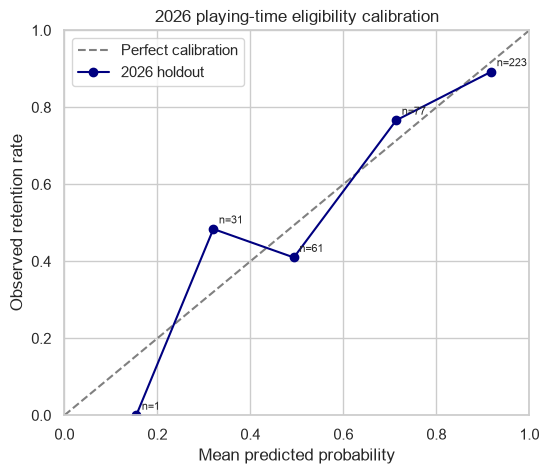

In [3]:
holdout['probability_bin'] = pd.cut(holdout['eligibility_probability'], bins=[0, .2, .4, .6, .8, 1], include_lowest=True)
calibration = holdout.groupby('probability_bin', observed=False).agg(
    n=('next_eligible_150', 'size'),
    predicted=('eligibility_probability', 'mean'),
    observed=('next_eligible_150', 'mean'),
).reset_index()
display(calibration.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
ax.plot(calibration['predicted'], calibration['observed'], 'o-', color='navy', label='2026 holdout')
for _, row in calibration.iterrows():
    ax.annotate(f"n={int(row['n'])}", (row['predicted'], row['observed']), xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted probability', ylabel='Observed retention rate', title='2026 playing-time eligibility calibration')
ax.legend()
plt.show()

## Conditional wRC+ predictions versus actual outcomes

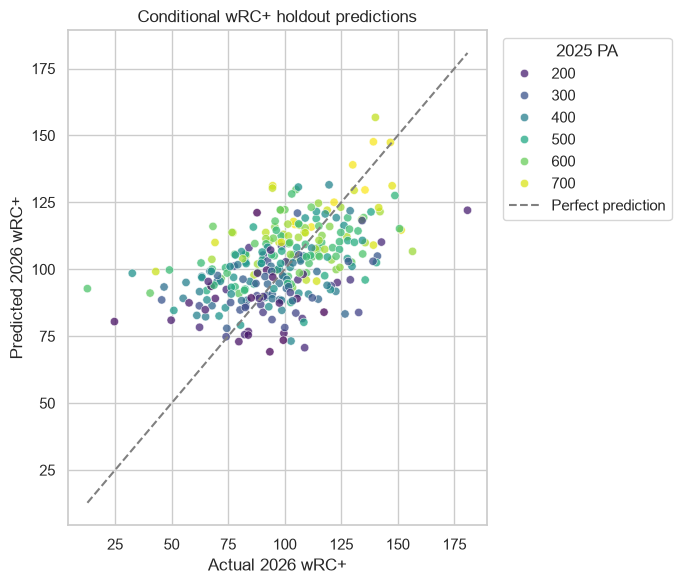

In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=performance_test, x='next_wrc_plus', y='predicted_wrc_plus', hue='pa_fg', palette='viridis', alpha=.75, ax=ax)
lower = min(performance_test['next_wrc_plus'].min(), performance_test['predicted_wrc_plus'].min())
upper = max(performance_test['next_wrc_plus'].max(), performance_test['predicted_wrc_plus'].max())
ax.plot([lower, upper], [lower, upper], '--', color='gray', label='Perfect prediction')
ax.set(xlabel='Actual 2026 wRC+', ylabel='Predicted 2026 wRC+', title='Conditional wRC+ holdout predictions')
ax.legend(title='2025 PA', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Error by prior-season playing time

,pa_group,n,mae
0,150-249,38,19.76
1,250-399,65,15.49
2,400+,195,16.98


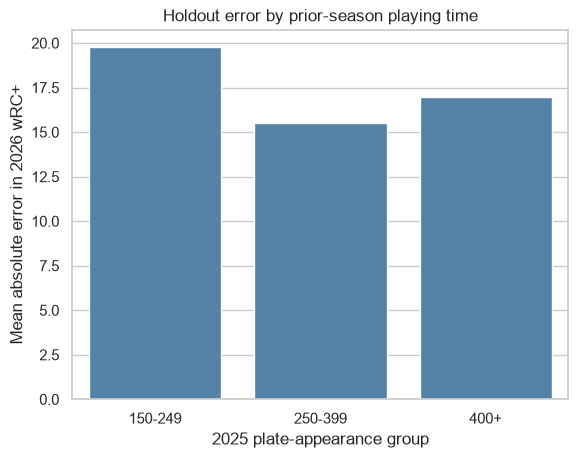

In [5]:
performance_test['pa_group'] = pd.cut(performance_test['pa_fg'], bins=[150, 250, 400, np.inf], labels=['150-249', '250-399', '400+'], right=False)
performance_test['absolute_error'] = (performance_test['next_wrc_plus'] - performance_test['predicted_wrc_plus']).abs()
error_by_pa = performance_test.groupby('pa_group', observed=False).agg(n=('fg_id', 'size'), mae=('absolute_error', 'mean')).reset_index()
display(error_by_pa.round(2))
sns.barplot(data=error_by_pa, x='pa_group', y='mae', color='steelblue')
plt.xlabel('2025 plate-appearance group')
plt.ylabel('Mean absolute error in 2026 wRC+')
plt.title('Holdout error by prior-season playing time')
plt.show()